Train: (800, 1, 24, 24)
Foreground pixel ratio: 2.154%
BCE        | IoU=0.979 | pixel acc=1.000
BCE + Dice | IoU=0.982 | pixel acc=1.000

[Segmentation tensor shapes]
Input:        (8, 1, 24, 24)
Feature maps: (8, 16, 24, 24)
Mask logits:  (8, 1, 24, 24)
Probability:  (8, 1, 24, 24)
True box:      (8, 6, 12, 10)
Predicted box: (8, 6, 12, 10)


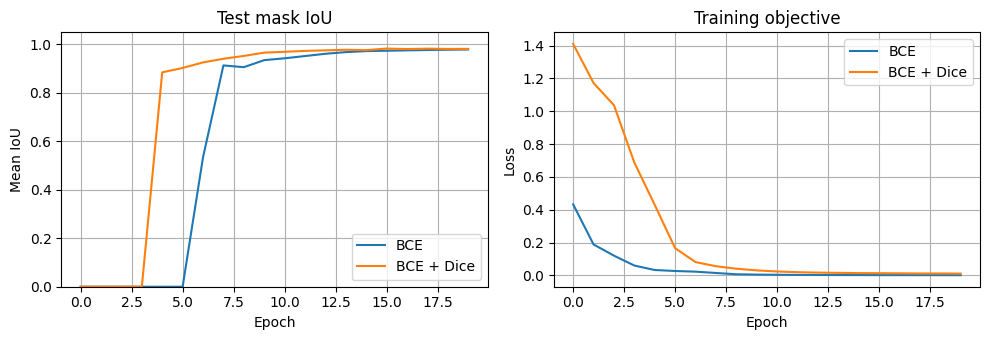

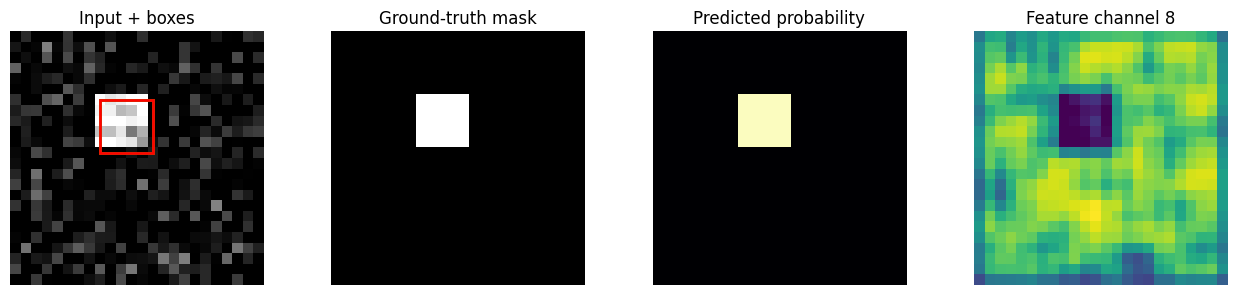

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(9)
torch.set_num_threads(1)

IMAGE_SIZE = 24
EPOCHS = 20
BATCH_SIZE = 64
THRESHOLD = 0.5



# --------------------------------------------------
## 1. Small rectangular segmentation data
# --------------------------------------------------
def make_dataset(num_samples, seed):
    generator = torch.Generator().manual_seed(seed)

    images = 0.18 * torch.randn(
        num_samples, 1, IMAGE_SIZE, IMAGE_SIZE,
        generator=generator,
    )

    masks = torch.zeros_like(images)

    for i in range(num_samples):
        height = torch.randint(
            2, 6, (), generator=generator
        ).item()

        width = torch.randint(
            2, 6, (), generator=generator
        ).item()

        top = torch.randint(
            1, IMAGE_SIZE - height - 1,
            (),
            generator=generator,
        ).item()

        left = torch.randint(
            1, IMAGE_SIZE - width - 1,
            (),
            generator=generator,
        ).item()

        masks[
            i, 0,
            top:top + height,
            left:left + width,
        ] = 1.0

        intensity = (
            0.65
            + 0.30 * torch.rand(
                (), generator=generator
            ).item()
        )

        images[i] += intensity * masks[i]

    images = images.clamp(0.0, 1.0)
    return images, masks


train_images, train_masks = make_dataset(800, seed=1)
test_images, test_masks = make_dataset(200, seed=2)

positive_ratio = train_masks.mean().item()

print("Train:", tuple(train_images.shape))
print("Foreground pixel ratio:", f"{positive_ratio:.3%}")



# --------------------------------------------------
## 2. A Small FCN That Preserves Resolution
# --------------------------------------------------
class TinySegmenter(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
        )

        self.mask_head = nn.Conv2d(
            16, 1, kernel_size=1
        )

    def forward(self, x):
        features = self.features(x)
        logits = self.mask_head(features)
        return logits


bce_criterion = nn.BCEWithLogitsLoss()


def dice_loss(logits, targets, epsilon=1e-6):
    probabilities = torch.sigmoid(logits)

    intersection = (
        probabilities * targets
    ).sum(dim=(1, 2, 3))

    denominator = (
        probabilities + targets
    ).sum(dim=(1, 2, 3))

    dice = (
        2 * intersection + epsilon
    ) / (
        denominator + epsilon
    )

    return 1.0 - dice.mean()



# --------------------------------------------------
## 3. IoU and pixel accuracy
# --------------------------------------------------
@torch.no_grad()
def evaluate(model):
    model.eval()

    logits = model(test_images)
    predictions = (
        torch.sigmoid(logits) >= THRESHOLD
    ).float()

    intersection = (
        predictions * test_masks
    ).sum(dim=(1, 2, 3))

    union = (
        (predictions + test_masks) > 0
    ).float().sum(dim=(1, 2, 3))

    mean_iou = (
        (intersection + 1e-6)
        / (union + 1e-6)
    ).mean().item()

    pixel_accuracy = (
        predictions == test_masks
    ).float().mean().item()

    return mean_iou, pixel_accuracy



# --------------------------------------------------
## 4. Training with BCE and BCE + Dice
# --------------------------------------------------
def train_model(loss_mode):
    torch.manual_seed(20)
    model = TinySegmenter()

    loader = DataLoader(
        TensorDataset(train_images, train_masks),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(30),
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.003,
    )

    loss_history = []
    iou_history = []

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0

        for images, masks in loader:
            logits = model(images)
            bce = bce_criterion(logits, masks)

            if loss_mode == "bce":
                loss = bce
            else:
                loss = bce + dice_loss(logits, masks)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(images)

        mean_iou, _ = evaluate(model)

        loss_history.append(
            total_loss / len(loader.dataset)
        )
        iou_history.append(mean_iou)

    final_iou, pixel_accuracy = evaluate(model)

    return {
        "model": model,
        "loss": loss_history,
        "iou": iou_history,
        "final_iou": final_iou,
        "pixel_accuracy": pixel_accuracy,
    }


bce_result = train_model("bce")
dice_result = train_model("bce_dice")

for name, result in (
    ("BCE", bce_result),
    ("BCE + Dice", dice_result),
):
    print(
        f"{name:10s} | "
        f"IoU={result['final_iou']:.3f} | "
        f"pixel acc={result['pixel_accuracy']:.3f}"
    )



# --------------------------------------------------
## 5. Verification of tensor shapes
# --------------------------------------------------
model = dice_result["model"]
example = test_images[:8]

with torch.no_grad():
    feature_maps = model.features(example)
    logits = model.mask_head(feature_maps)
    probabilities = torch.sigmoid(logits)

print("\n[Segmentation tensor shapes]")
print("Input:       ", tuple(example.shape))
print("Feature maps:", tuple(feature_maps.shape))
print("Mask logits: ", tuple(logits.shape))
print("Probability: ", tuple(probabilities.shape))

assert feature_maps.shape == (8, 16, 24, 24)
assert logits.shape == test_masks[:8].shape
assert probabilities.min() >= 0
assert probabilities.max() <= 1
assert torch.isfinite(logits).all()



# --------------------------------------------------
## 6. Extracting bounding boxes from predicted masks
# --------------------------------------------------
def mask_to_box(binary_mask):
    rows, columns = torch.where(binary_mask)

    if len(rows) == 0:
        return None

    return (
        columns.min().item(),
        rows.min().item(),
        columns.max().item(),
        rows.max().item(),
    )


sample_index = 0

with torch.no_grad():
    sample_probability = torch.sigmoid(
        model(test_images[sample_index:sample_index + 1])
    )[0, 0]

sample_prediction = (
    sample_probability >= THRESHOLD
)

true_box = mask_to_box(
    test_masks[sample_index, 0].bool()
)

predicted_box = mask_to_box(
    sample_prediction
)

print("True box:     ", true_box)
print("Predicted box:", predicted_box)



# --------------------------------------------------
## 7. Learning Curves and Visualization of Internal Representations
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(bce_result["iou"], label="BCE")
axes[0].plot(dice_result["iou"], label="BCE + Dice")
axes[0].set_title("Test mask IoU")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean IoU")
axes[0].set_ylim(0.0, 1.05)
axes[0].grid(True)
axes[0].legend()

axes[1].plot(bce_result["loss"], label="BCE")
axes[1].plot(dice_result["loss"], label="BCE + Dice")
axes[1].set_title("Training objective")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


with torch.no_grad():
    sample_features = model.features(
        test_images[sample_index:sample_index + 1]
    )[0]

channel = sample_features.var(
    dim=(1, 2)
).argmax().item()

fig, axes = plt.subplots(1, 4, figsize=(13, 3))

axes[0].imshow(
    test_images[sample_index, 0],
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[0].set_title("Input + boxes")

for box, color in (
    (true_box, "lime"),
    (predicted_box, "red"),
):
    if box is not None:
        x1, y1, x2, y2 = box
        axes[0].add_patch(Rectangle(
            (x1, y1),
            x2 - x1 + 1,
            y2 - y1 + 1,
            fill=False,
            edgecolor=color,
            linewidth=2,
        ))

axes[1].imshow(
    test_masks[sample_index, 0],
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Ground-truth mask")

axes[2].imshow(
    sample_probability,
    cmap="magma",
    vmin=0,
    vmax=1,
)
axes[2].set_title("Predicted probability")

axes[3].imshow(
    sample_features[channel],
    cmap="viridis",
)
axes[3].set_title(f"Feature channel {channel}")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()